# Practice the Maths part

Mean Square Error (MSE) is a common metric used to evaluate the performance of regression models. It measures the average squared difference between the predicted values and the actual values. A lower MSE indicates a better fit of the model to the data.

Example with a fixed 3 data points:

In [18]:
import numpy as np

# Actual values and the model's predictions
actual = np.array([10, 20, 30])
predicted = np.array([8, 17, 29])

# Calculate each step of MSE
errors = actual - predicted
squared_errors = errors ** 2
n = len(actual)
mse = squared_errors.sum() / n

print("Errors:", errors)
print("Squared errors:", squared_errors)
print("Sum of squared errors:", squared_errors.sum())
print("Number of data points:", n)
print(f"MSE: {mse:.2f}")

# NumPy can also calculate the average directly
print(f"MSE using np.mean: {np.mean(squared_errors):.2f}")

Errors: [2 3 1]
Squared errors: [4 9 1]
Sum of squared errors: 14
Number of data points: 3
MSE: 4.67
MSE using np.mean: 4.67


Example with more data points and random values. Control the randomness with a seed for reproducibility.
For more noise, increase the scale in the normal distribution. For less noise decrease the scale.

In [19]:
import numpy as np

n = 100  # Number of values
rng = np.random.default_rng(seed=42)

# Generate n random integers between 0 and 100 (100 excluded)
actual = rng.integers(0, 100, size=n)

# Make predictions by adding random noise to the actual values
predicted = actual + rng.normal(
    loc=0,    # Mean of the normal distribution; centers the random noise at 0
    scale=5,  # Standard deviation of the distribution; controls how spread out the noise is
    size=n    # Number/shape of random values to generate; here, generate n noise values
)

squared_errors = (actual - predicted) ** 2
mse = np.mean(squared_errors)  # Equivalent to squared_errors.sum() / n

print("Actual values:", actual)
print("Predicted values:", np.round(predicted, 2))
#print("Squared errors:", np.round(squared_errors, 2))
#print("Sum of squared errors:", np.round(squared_errors.sum(), 2))
print(f"MSE: {mse:.2f}")

Actual values: [ 8 77 65 43 43 85  8 69 20  9 52 97 73 76 71 78 51 12 83 45 50 37 18 92
 78 64 40 82 54 44 45 22  9 55 88  6 85 82 27 63 16 75 70 35  6 97 44 89
 67 77 75 19 36 46 49  4 54 15 74 68 92 74 36 96 41 32 90 37  7 46 79 18
 46 12 68 47 33 22 56 66 94 43 16 83 62 70  9 31 76 83 43 80 84 38 89 28
 23 68 63 13]
Predicted values: [ 11.39  77.34  66.45  46.16  35.71  83.4    5.65  65.81  18.62  16.47
  47.67 101.84  64.59  74.33  71.81  80.93  54.56  15.97  81.26  42.69
  54.29  36.04  11.62  86.33  73.4   66.49  40.71  85.45  51.86  44.79
  48.13  20.45  11.28  51.69  86.18   4.09  79.02  84.43  24.65  63.06
  18.4   77.23  73.33  34.51   3.88  96.6   35.56  81.76  60.39  72.01
  77.    14.47  34.11  52.5   47.22   7.69  49.33  13.97  69.25  66.3
  96.2   65.36  38.17  97.19  38.03  24.77  90.36  34.35   8.16  46.11
  87.01  16.8   40.88  12.9   69.1   53.8   37.18  23.78  63.32  60.06
  90.8   38.37  14.05  76.12  65.18  68.89   1.65  25.92  77.57  87.19
  52.98  94.57  86.07  

The line of best fit is useless in this scenario.

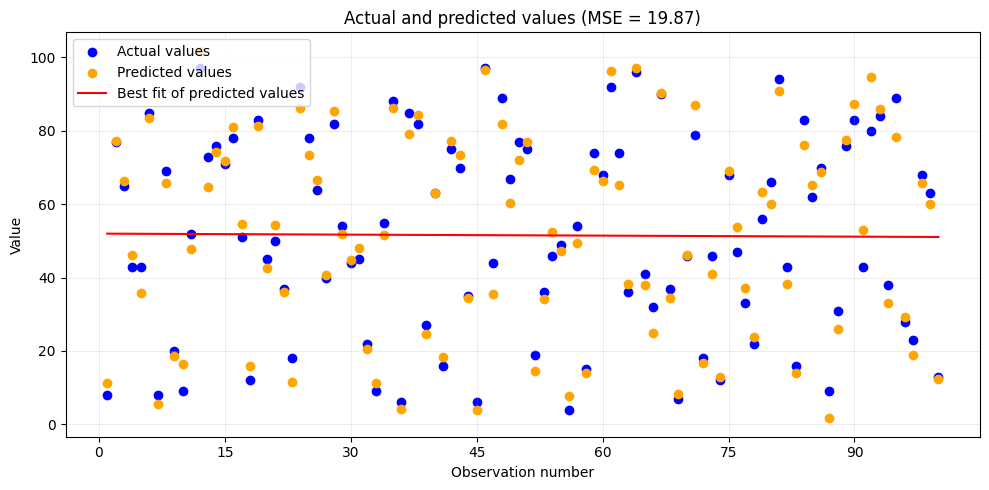

In [20]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Observation numbers: 1, 2, ..., n
x = np.arange(1, n + 1)

# Fit a straight line to the predicted values
slope, intercept = np.polyfit(x, predicted, deg=1)
best_fit = slope * x + intercept

'''
plt.figure(figsize=(10, 5))

plt.scatter(x, actual, label="Actual values", color="blue")
plt.scatter(x, predicted, label="Predicted values", color="orange")
plt.plot(x, best_fit, label="Best fit of predicted values", color="red")

plt.xlabel("Observation number")
plt.ylabel("Value")
plt.title(f"Actual and predicted values (MSE = {mse:.2f})")
plt.xticks(x)
plt.legend()
plt.grid(alpha=0.3)
'''

fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(x, actual, label="Actual values", color="blue")
ax.scatter(x, predicted, label="Predicted values", color="orange")
ax.plot(x, best_fit, label="Best fit of predicted values", color="red")

ax.set_xlabel("Observation number")
ax.set_ylabel("Value")
ax.set_title(f"Actual and predicted values (MSE = {mse:.2f})")

# Fix the x-axis ticks to show up to 10 ticks, and only integer values
ax.xaxis.set_major_locator(MaxNLocator(nbins=10, integer=True))

ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()

plt.show()

This provides a better representation of the model's performance. The scatter plot shows how close the predicted values are to the actual values, while the line of best fit for the predicted values gives an idea of the overall trend. The MSE value quantifies the average squared difference between the actual and predicted values, with a lower MSE indicating better model performance.

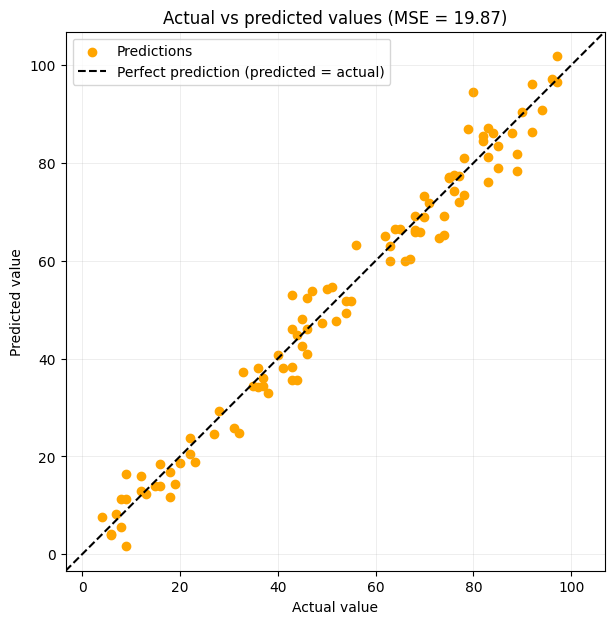

In [21]:
import matplotlib.pyplot as plt

# Limits shared by both axes
lower = min(actual.min(), predicted.min()) - 5
upper = max(actual.max(), predicted.max()) + 5

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(actual, predicted, color="orange", label="Predictions")
ax.plot(
    [lower, upper],
    [lower, upper],
    "k--",
    label="Perfect prediction (predicted = actual)"
)

ax.set(
    xlabel="Actual value",
    ylabel="Predicted value",
    title=f"Actual vs predicted values (MSE = {mse:.2f})",
    xlim=(lower, upper),
    ylim=(lower, upper)
)
ax.set_aspect("equal", adjustable="box")
ax.legend()
ax.grid(alpha=0.3)
plt.show()